### 1. Setup

In [1]:
# importing the dependencies
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# configurations

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
sns.set_theme(style='darkgrid')
RANDOM_STATE = 42

### 2. Load data

In [3]:
df = pd.read_csv('breast_cancer_dataset.csv')

In [4]:
df.shape

(569, 32)

In [5]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119
1,842517,M,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089
2,84300903,M,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088
3,84348301,M,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173
4,84358402,M,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077


In [6]:
df = df.drop('id', axis=1)

In [7]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119
1,M,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089
2,M,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088
3,M,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173
4,M,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077


### 3. Exploratory data analysis

In [8]:
df.columns

Index(['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [12]:
# check presence of missing values
df.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [14]:
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063,0.405,1.217,2.866,40.337,0.007,0.025,0.032,0.012,0.021,0.004,16.269,25.677,107.261,880.583,0.132,0.254,0.272,0.115,0.290,0.084
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007,0.277,0.552,2.022,45.491,0.003,0.018,0.030,0.006,0.008,0.003,4.833,6.146,33.603,569.357,0.023,0.157,0.209,0.066,0.062,0.018
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050,0.112,0.360,0.757,6.802,0.002,0.002,0.000,0.000,0.008,0.001,7.930,12.020,50.410,185.200,0.071,0.027,0.000,0.000,0.157,0.055
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058,0.232,0.834,1.606,17.850,0.005,0.013,0.015,0.008,0.015,0.002,13.010,21.080,84.110,515.300,0.117,0.147,0.115,0.065,0.250,0.071
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062,0.324,1.108,2.287,24.530,0.006,0.020,0.026,0.011,0.019,0.003,14.970,25.410,97.660,686.500,0.131,0.212,0.227,0.100,0.282,0.080
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066,0.479,1.474,3.357,45.190,0.008,0.032,0.042,0.015,0.023,0.005,18.790,29.720,125.400,1084.000,0.146,0.339,0.383,0.161,0.318,0.092
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097,2.873,4.885,21.980,542.200,0.031,0.135,0.396,0.053,0.079,0.030,36.040,49.540,251.200,4254.000,0.223,1.058,1.252,0.291,0.664,0.207


In [16]:
# check if there is any encoded missing values - top repeated values
'''
for col in df.columns:
    print(df[col].value_counts().head(10))
'''

'\nfor col in df.columns:\n    print(df[col].value_counts().head(10))\n'

In [17]:
# identify duplicate rows
duplicate_mask = df.duplicated()
num_duplicates = duplicate_mask.sum()
print("Number of duplicate rows: ", num_duplicates)
print("Duplicated row: ", df[duplicate_mask])

# If you want to remove duplicates:
# df_no_duplicate = df.drop_duplicates()
# print("Shape after no duplicates ", df_no_duplicate.shape)

Number of duplicate rows:  0
Duplicated row:  Empty DataFrame
Columns: [diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_worst, compactness_worst, concavity_worst, concave points_worst, symmetry_worst, fractal_dimension_worst]
Index: []


In [18]:
# class distribution
print(df['diagnosis'].value_counts())
print("-"*50)
print(df['diagnosis'].value_counts(normalize=True)*100)

diagnosis
B    357
M    212
Name: count, dtype: int64
--------------------------------------------------
diagnosis
B   62.742
M   37.258
Name: proportion, dtype: float64


In [19]:
# encode categorical column
df['diagnosis'] = df['diagnosis'].map({'B' : 0, 'M' : 1})

In [20]:
# class distribution
print(df['diagnosis'].value_counts())
print("-"*50)
print(df['diagnosis'].value_counts(normalize=True)*100)

diagnosis
0    357
1    212
Name: count, dtype: int64
--------------------------------------------------
diagnosis
0   62.742
1   37.258
Name: proportion, dtype: float64


In [21]:
df.groupby('diagnosis').mean()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
diagnosis,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,12.147,17.915,78.075,462.790,0.092,0.080,0.046,0.026,0.174,0.063,0.284,1.220,2.000,21.135,0.007,0.021,0.026,0.010,0.021,0.004,13.380,23.515,87.006,558.899,0.125,0.183,0.166,0.074,0.270,0.079
1,17.463,21.605,115.365,978.376,0.103,0.145,0.161,0.088,0.193,0.063,0.609,1.211,4.324,72.672,0.007,0.032,0.042,0.015,0.020,0.004,21.135,29.318,141.370,1422.286,0.145,0.375,0.451,0.182,0.323,0.092


### Data visualization

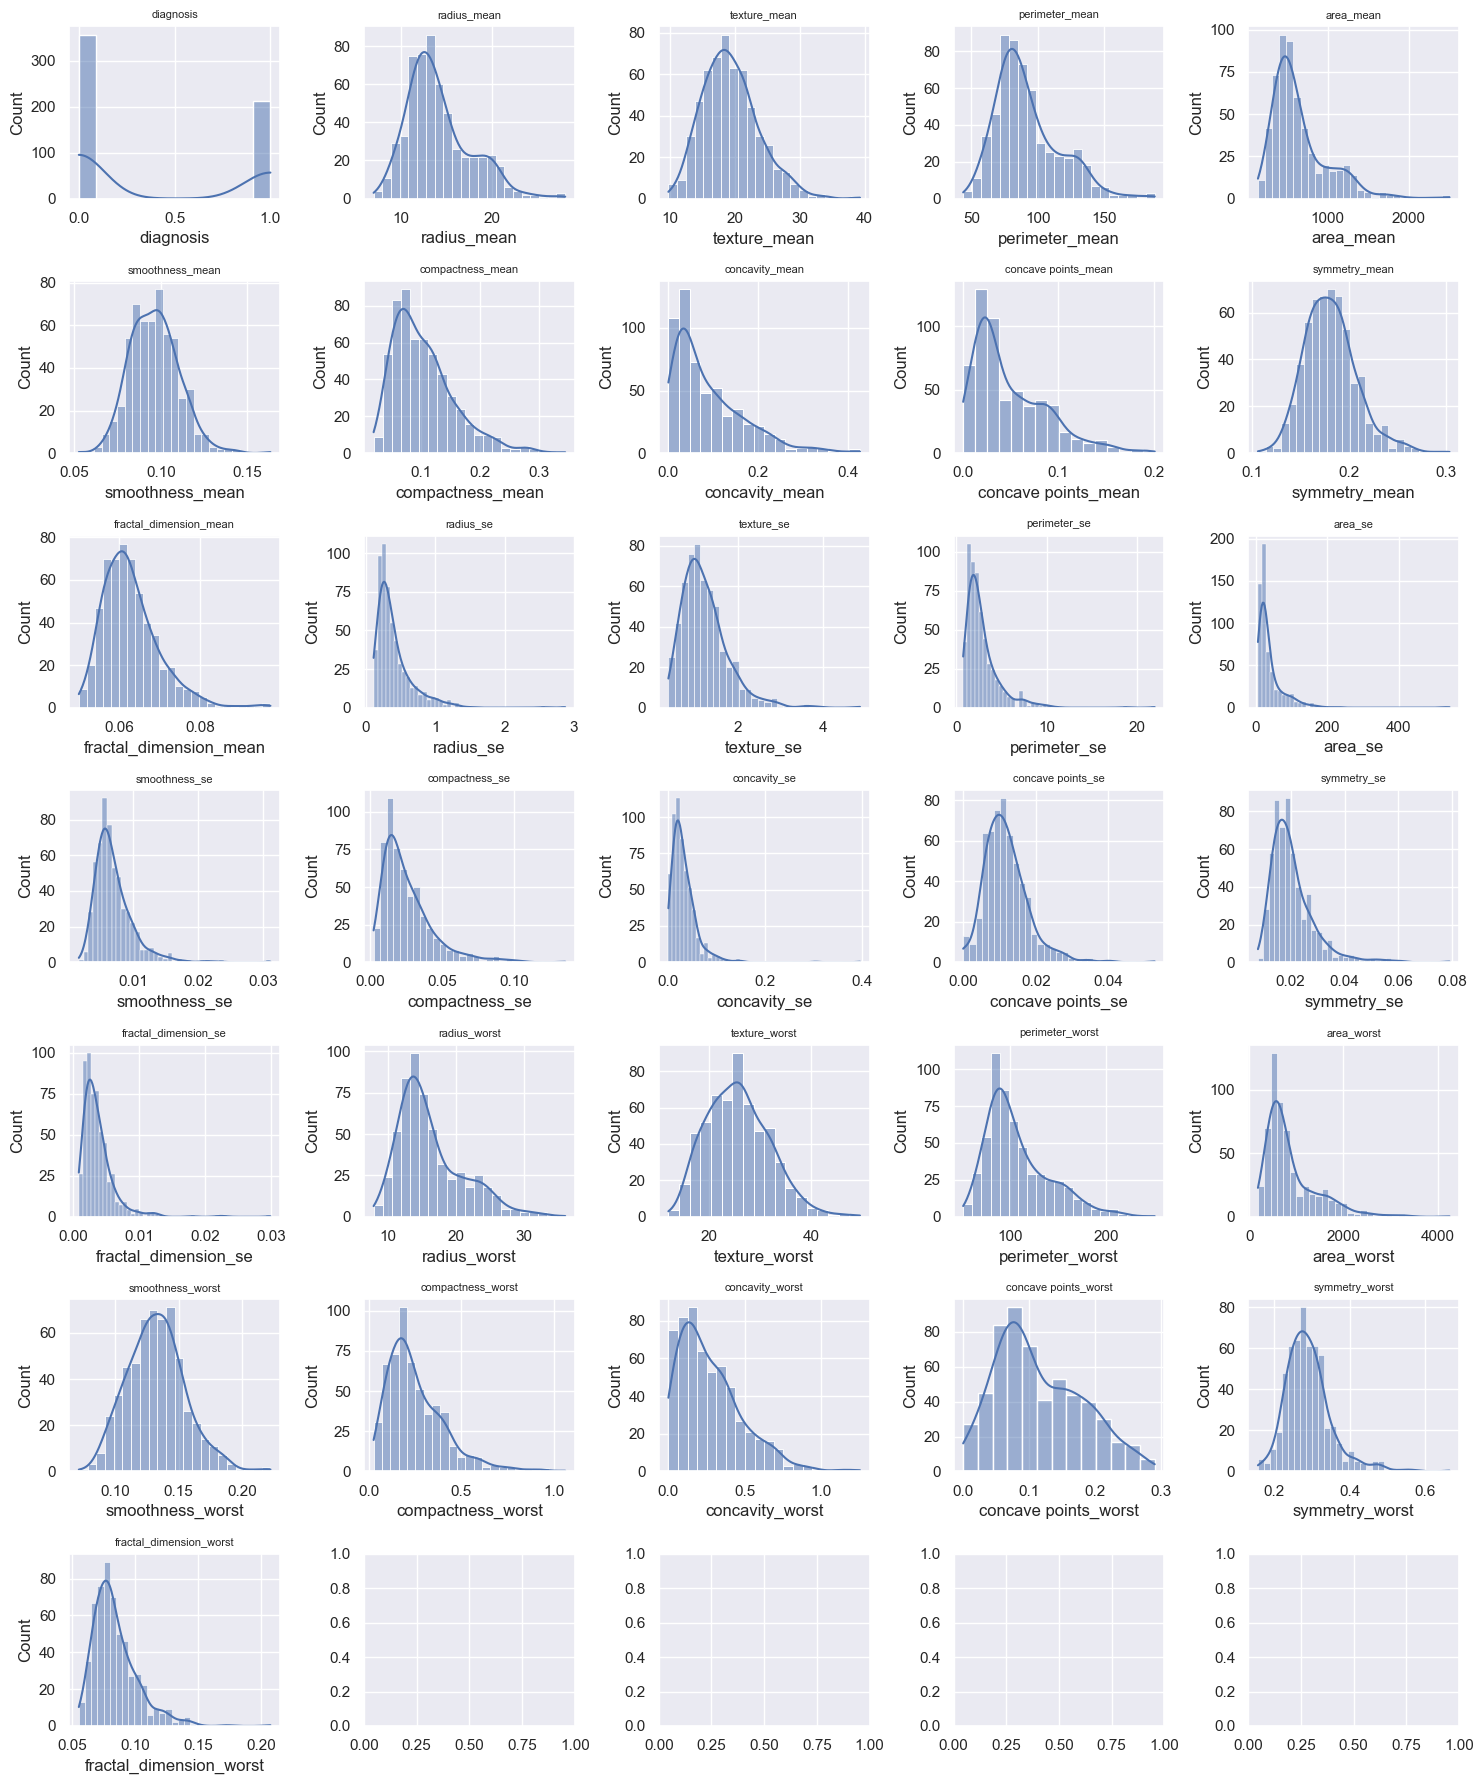

In [22]:
fig, axes = plt.subplots(7, 5, figsize=(15, 18))
axes = axes.flatten()
for i, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)
plt.tight_layout()
plt.show()

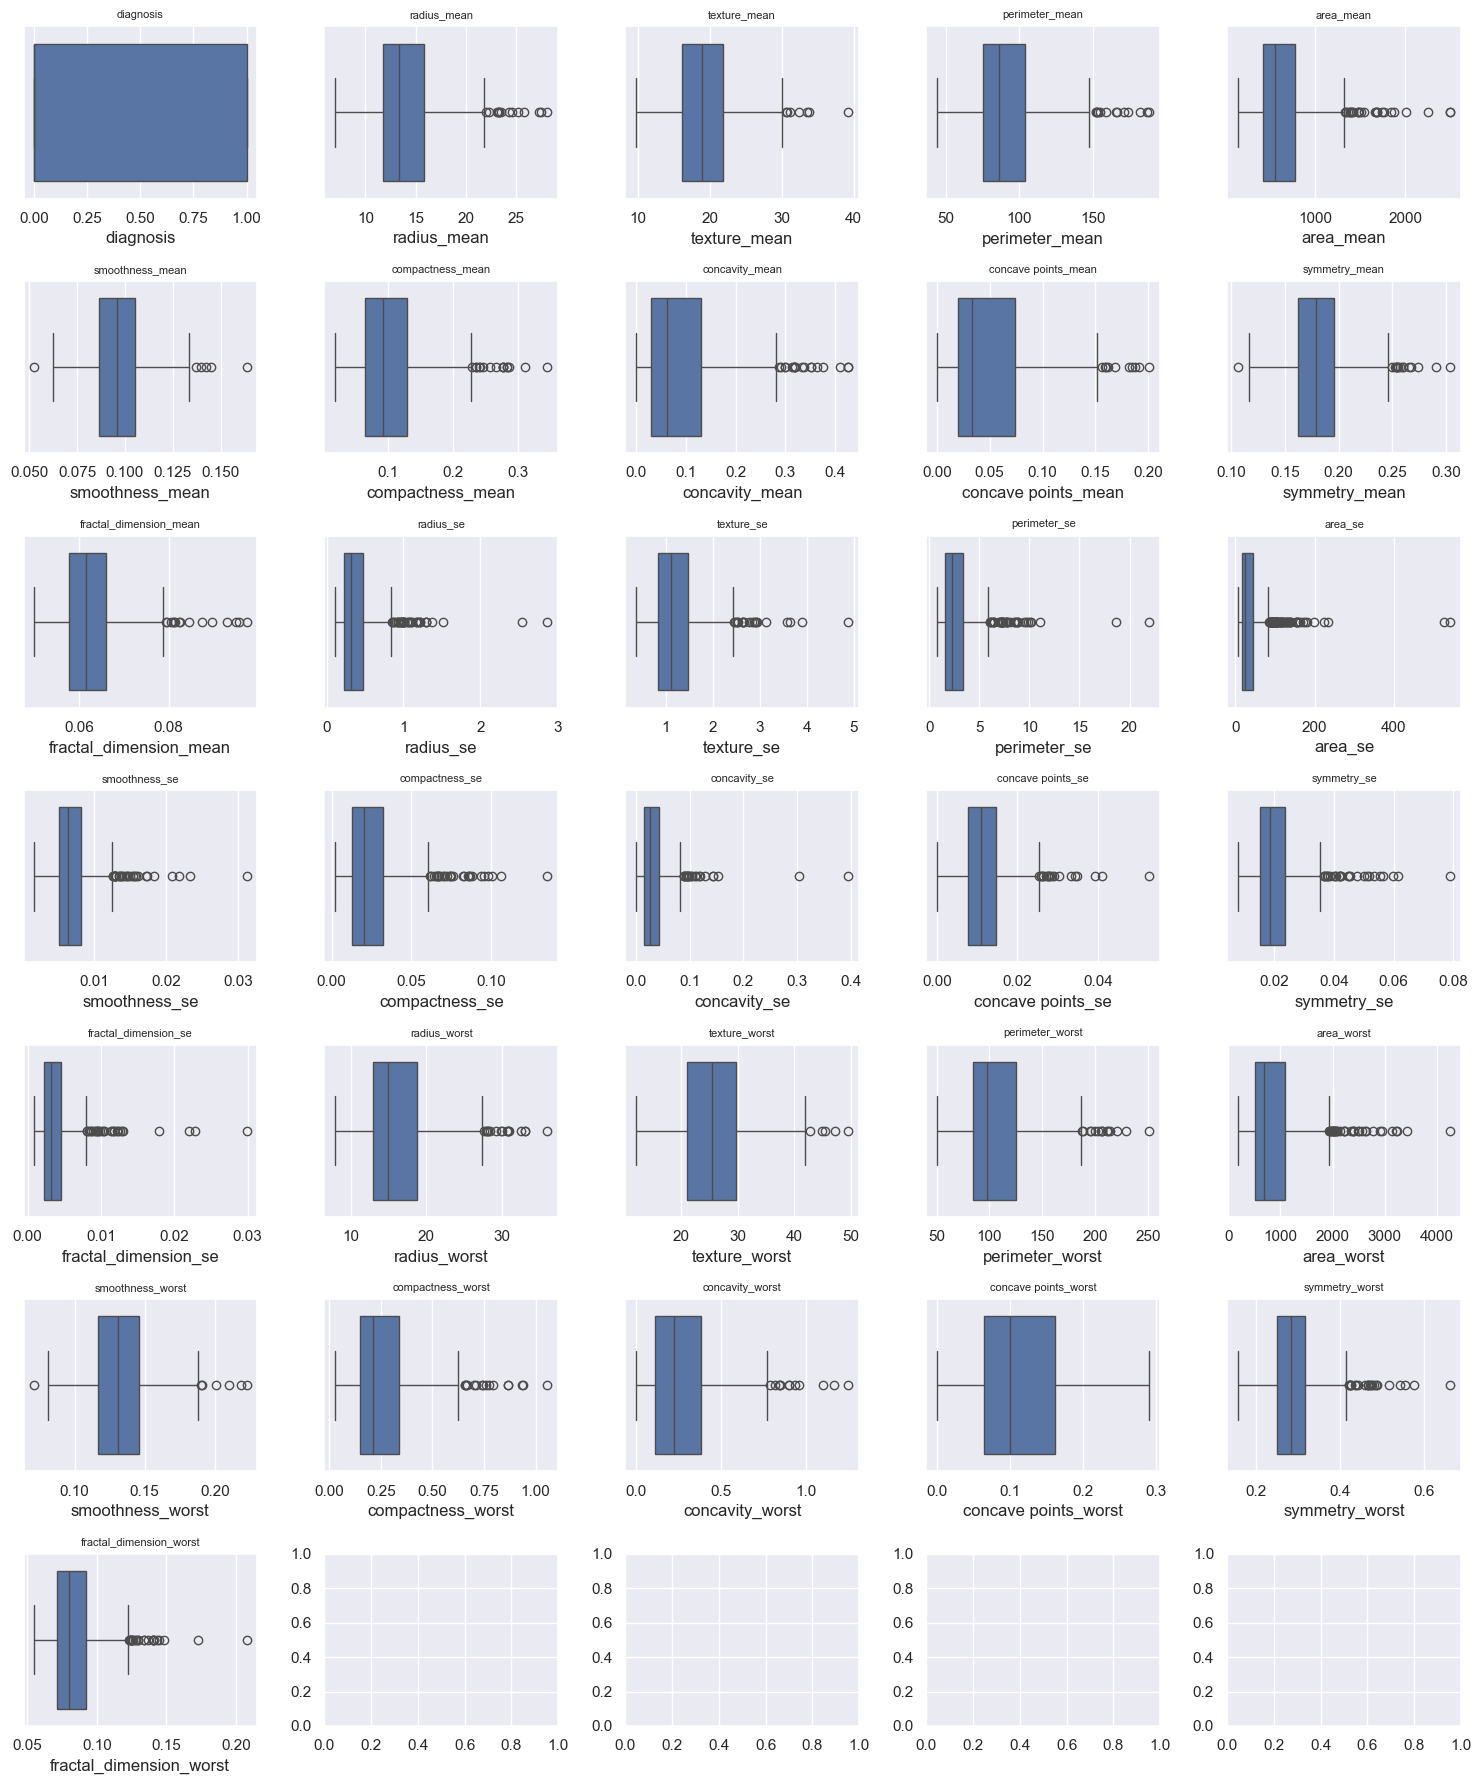

In [23]:
# outlier analysis - box plot
fig, axes = plt.subplots(7, 5, figsize=(15, 18))
axes = axes.flatten()
for i, col in enumerate(df.columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
plt.tight_layout()
plt.show()

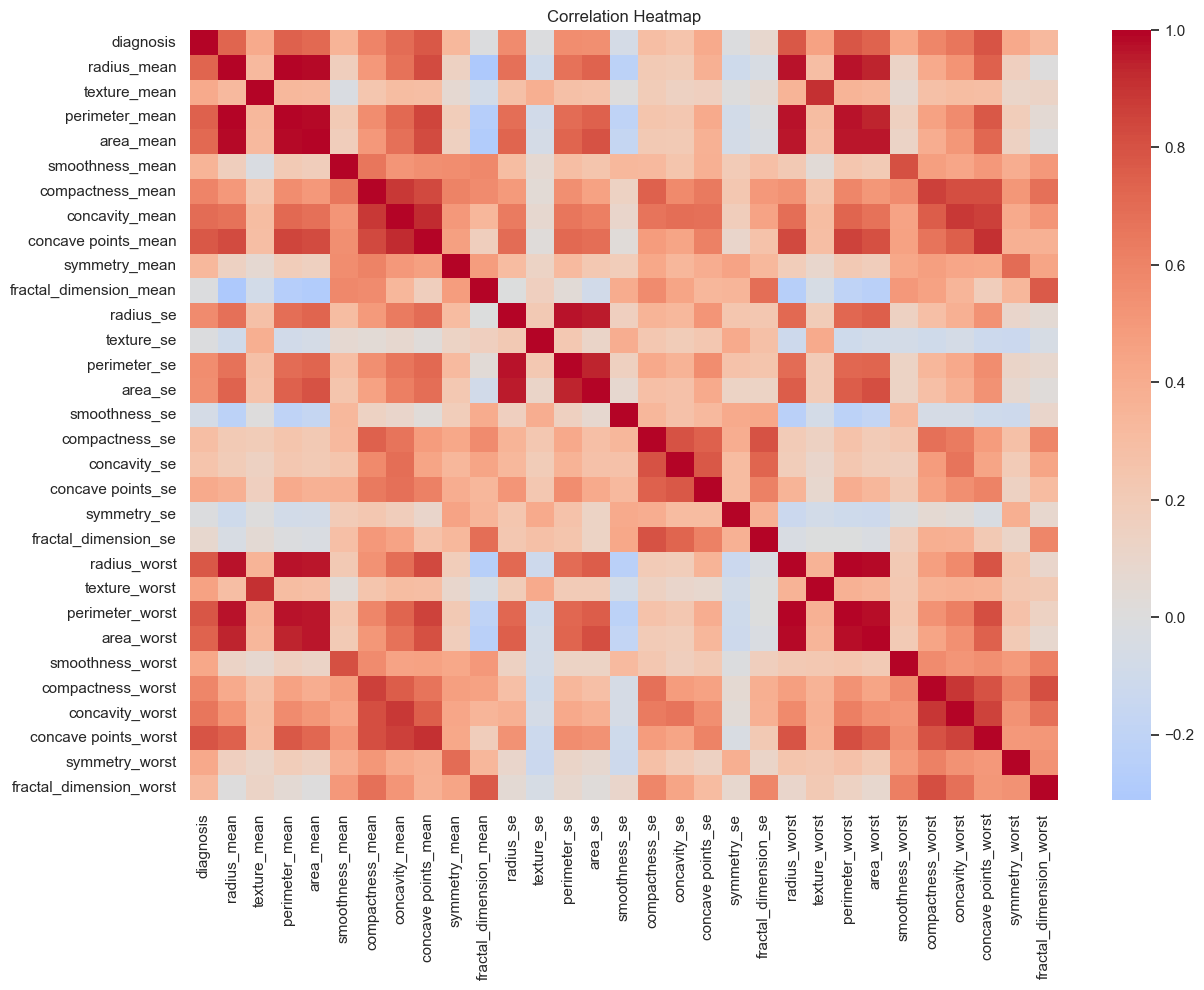

In [24]:
# dentify presence of highly correlated columns & feature relationships
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title('Correlation Heatmap')
plt.show()

### 4. Data Preprocessing

In [25]:
# separate data into features and labels
x = df.drop('diagnosis', axis=1)
y = df['diagnosis']

In [28]:
# train test split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

In [29]:
print("Dataset size: ", x.shape)
print("Train dataset size: ", x_train.shape)
print("Test dataset size: ", x_test.shape)

Dataset size:  (569, 30)
Train dataset size:  (455, 30)
Test dataset size:  (114, 30)


### 5. Baseline model - Logistic Regression

In [30]:
scaler = StandardScaler()

In [35]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [32]:
model = LogisticRegression()

In [33]:
#training the model
model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [34]:
# training accuracy
model.score(x_train_scaled, y_train)

0.9868131868131869

In [36]:
# testing accuracy
model.score(x_test_scaled, y_test)

0.9649122807017544

### 6. Model Optimization

In [40]:
# pipeline creation
pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA()),
        ("model", SVC(kernel="rbf"))
    ]
)

In [38]:
# grid of hyperparameters
param_grid = [
    {
        "pca__n_components" : [10, 15, 20, 25, 30],
        "model__C" : [0.1, 1, 10, 100, 1000],
        "model__gamma" : [0.001, 0.01, 0.1, 1, "scale"]
    }
]

In [39]:
# cross-validation setup (used inside grid search cv)
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

In [41]:
# hyperparameter tuning
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=skf,
    n_jobs=-1
)

In [42]:
grid_search.fit(x_train, y_train)

,estimator,"Pipeline(step...del', SVC())])"
,param_grid,"[{'model__C': [0.1, 1, ...], 'model__gamma': [0.001, 0.01, ...], 'pca__n_components': [10, 15, ...]}]"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [43]:
print("Hyperparameter tuning results:")
print("Best params: ", grid_search.best_params_)
print("Best score: ", grid_search.best_score_)

Hyperparameter tuning results:
Best params:  {'model__C': 10, 'model__gamma': 'scale', 'pca__n_components': 10}
Best score:  0.9647058823529411


### 7. Train with best params

In [44]:
best_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=10)),
        ("model", SVC(kernel="rbf", C=10, gamma='scale'))
    ]
)

In [45]:
# train the pipeline
best_pipeline.fit(x_train, y_train)

,steps,"[('scaler', ...), ('pca', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_components,10
,copy,True
,whiten,False
,svd_solver,'auto'


### 8. Model Evaluation

In [46]:
# training data predictions
y_train_pred = best_pipeline.predict(x_train)

In [47]:
train_acc = accuracy_score(y_train_pred, y_train)
print(f"Training accuracy is: {round(train_acc*100, 2)}%")

Training accuracy is: 98.9%


Text(0.5, 1.0, 'Confusion Matrix Heatmap')

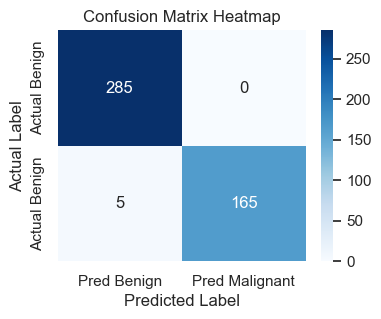

In [48]:
# confusion matrix
cm = confusion_matrix(y_train, y_train_pred)

plt.figure(figsize=(4,3))
# heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Benign"]
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix Heatmap')

In [49]:
print("Training classification report")
print(classification_report(y_train, y_train_pred))

Training classification report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       285
           1       1.00      0.97      0.99       170

    accuracy                           0.99       455
   macro avg       0.99      0.99      0.99       455
weighted avg       0.99      0.99      0.99       455



In [50]:
# test data prediction
y_test_pred = best_pipeline.predict(x_test)

In [51]:
test_acc = accuracy_score(y_test, y_test_pred)
print(f"Test accuracy: {round(test_acc*100, 2)}%")

Test accuracy: 96.49%


Text(0.5, 1.0, 'Confusion Matrix Heatmap')

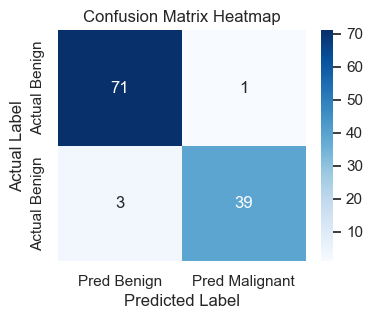

In [52]:
# confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(4,3))
# heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Benign"]
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix Heatmap')

In [53]:
print("Test classification report")
print(classification_report(y_test, y_test_pred))

Test classification report
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### 9. Build a inference system

In [54]:
def predict_cancer(input_features):
    input_df = pd.DataFrame(
        [input_features],
        columns=x_train.columns
    )
    prediction = best_pipeline.predict(input_df)
    print("Model prediction:", prediction)
    if(prediction[0] == 1):
        print("Diagnosis - Malignant 🔴")
    else:
        print("Diagnosis - Benign 🟢")

In [55]:
x_test.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
120,11.410,10.820,73.340,403.300,0.094,0.067,0.035,0.026,0.167,0.061,0.141,0.461,1.103,10.500,0.006,0.015,0.015,0.006,0.013,0.002,12.820,15.970,83.740,510.500,0.155,0.239,0.210,0.090,0.302,0.085
250,20.940,23.560,138.900,1364.000,0.101,0.161,0.271,0.131,0.221,0.059,1.004,0.821,6.372,137.900,0.005,0.039,0.095,0.019,0.024,0.005,25.580,27.000,165.300,2010.000,0.121,0.317,0.699,0.210,0.313,0.078
375,16.170,16.070,106.300,788.500,0.099,0.144,0.067,0.054,0.199,0.066,0.174,0.489,1.349,14.910,0.005,0.018,0.020,0.012,0.019,0.004,16.970,19.140,113.100,861.500,0.123,0.255,0.211,0.125,0.315,0.090
99,14.420,19.770,94.480,642.500,0.098,0.114,0.094,0.058,0.188,0.064,0.289,1.851,2.376,26.850,0.008,0.029,0.033,0.014,0.015,0.004,16.330,30.860,109.500,826.400,0.143,0.303,0.319,0.157,0.272,0.094
455,13.380,30.720,86.340,557.200,0.092,0.074,0.028,0.033,0.138,0.060,0.341,1.924,2.287,28.930,0.006,0.012,0.008,0.009,0.016,0.003,15.050,41.610,96.690,705.600,0.117,0.142,0.070,0.078,0.220,0.077


In [56]:
y_test.head()

120    0
250    1
375    0
99     1
455    0
Name: diagnosis, dtype: int64

In [57]:
# sample unknown data point - access from test data index
test_1 = x_test.loc[120].tolist()
predict_cancer(test_1)

Model prediction: [0]
Diagnosis - Benign 🟢


In [58]:
test_2 = x_test.loc[250].tolist()
predict_cancer(test_2)

Model prediction: [1]
Diagnosis - Malignant 🔴
